In [1]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as ticker
import matplotlib.patheffects as pe

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
filenames = ["BH_solve_ODE_plot_2026-10-05_12-26-24.txt",
             "BH_solve_ODE_plot_2026-10-05_12-32-27.txt",
             "BH_solve_ODE_plot_2026-10-05_16-31-07.txt",
             "BH_solve_ODE_plot_2026-10-06_12-01-16.txt",
             "BH_solve_ODE_plot_2026-10-06_11-03-17.txt"]
list_of_lines = []

for filename in filenames:
  file_path = '/content/drive/My Drive/Colab Notebooks/Project/ODE with Matrix Elements frfr/plot_data/'+filename
  try:
    with open(file_path, 'r') as f:
      text = f.read()
      list_of_lines.append(text.splitlines())
  except Exception as e:
    print(f"An error occurred: {e}")

In [4]:
xi_values = []
f_values = []
list_of_T_values = []
list_of_N_1s_values = []
list_of_N_2s_values = []
list_of_N_2p_values = []

for lines in list_of_lines:
  xi_values.append(float(lines[0].split(" ")[1]))
  f_values.append(float(lines[0].split(" ")[3]))

  T_values = []
  N_1s_values = []
  N_2s_values = []
  N_2p_values = []

  T_values = [float(x) for x in lines[1].split(" ")[:-1]]
  N_1s_values = [float(x) for x in lines[2].split(" ")[:-1]]
  N_2s_values = [float(x) for x in lines[3].split(" ")[:-1]]
  N_2p_values = [float(x) for x in lines[4].split(" ")[:-1]]

  list_of_T_values.append(np.array(T_values))
  list_of_N_1s_values.append(np.array(N_1s_values))
  list_of_N_2s_values.append(np.array(N_2s_values))
  list_of_N_2p_values.append(np.array(N_2p_values))

xi_values = np.array(xi_values)
f_values = np.array(f_values)

In [5]:
rho_0=0.38 #NFW density in GeV/cm^3
r_0=18600.0 #NFW scale in pc

def NFW(r):
    '''NFW density profile in GeV/cm^3. r is measured in pc'''
    return rho_0/(r/r_0 * (1+r/r_0)**2)

In [6]:
if (filename.startswith("Sun")):
  M_tilde = 1
  v_tilde = 1
  rho_tilde = NFW(8e3)/0.4
elif (filename.startswith("BH")):
  M_tilde = 10
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("IBH")):
  M_tilde = 1e3
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("IBH")):
  M_tilde = 1e5
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("star")):
  M_tilde = 10
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
else:
  print("Unkown astro_regime")

alpha_values = xi_values * 8e-4
alpha_0 = 7.5*1e-5
m_tilde_values = alpha_values/alpha_0/M_tilde
f_tilde_values = f_values/1e8

actual_N_k_values = 6.85591e61 * rho_tilde * m_tilde_values**(-6) * M_tilde**(-2) * v_tilde**(-1)
max_N_1s_values = 6.7e67 * f_tilde_values**2 * m_tilde_values**(-3) * M_tilde**(-1)
rho_crit_to_BG_1s_values = 2.9e4 * f_tilde_values**2 * m_tilde_values**4 * M_tilde**2 * rho_tilde**(-1)

list_of_N_1s_mass_values = []
list_of_N_2s_mass_values = []
list_of_N_2p_mass_values = []

list_of_N_1s_density_values = []
list_of_N_2s_density_values = []
list_of_N_2p_density_values = []

for i in range(len(xi_values)):
  # ratio of cloud mass to BH mass
  list_of_N_1s_mass_values.append(list_of_N_1s_values[i]*actual_N_k_values[i]*9e-81*m_tilde_values[i] / M_tilde)
  list_of_N_2s_mass_values.append(list_of_N_2s_values[i]*actual_N_k_values[i]*9e-81*m_tilde_values[i] / M_tilde)
  list_of_N_2p_mass_values.append(3*list_of_N_2p_values[i]*actual_N_k_values[i]*9e-81*m_tilde_values[i] / M_tilde)

  # new reasonabler density calculation (relative to BG at 1 r_b)
  list_of_N_1s_density_values.append(5.607e-53*list_of_N_1s_values[i]*actual_N_k_values[i]*alpha_values[i]**3*m_tilde_values[i]**4 / (0.4 * rho_tilde))
  list_of_N_2s_density_values.append(4.763e-54*list_of_N_2s_values[i]*actual_N_k_values[i]*alpha_values[i]**3*m_tilde_values[i]**4 / (0.4 * rho_tilde))
  list_of_N_2p_density_values.append(4.763e-54*list_of_N_2p_values[i]*actual_N_k_values[i]*alpha_values[i]**3*m_tilde_values[i]**4 / (0.4 * rho_tilde))

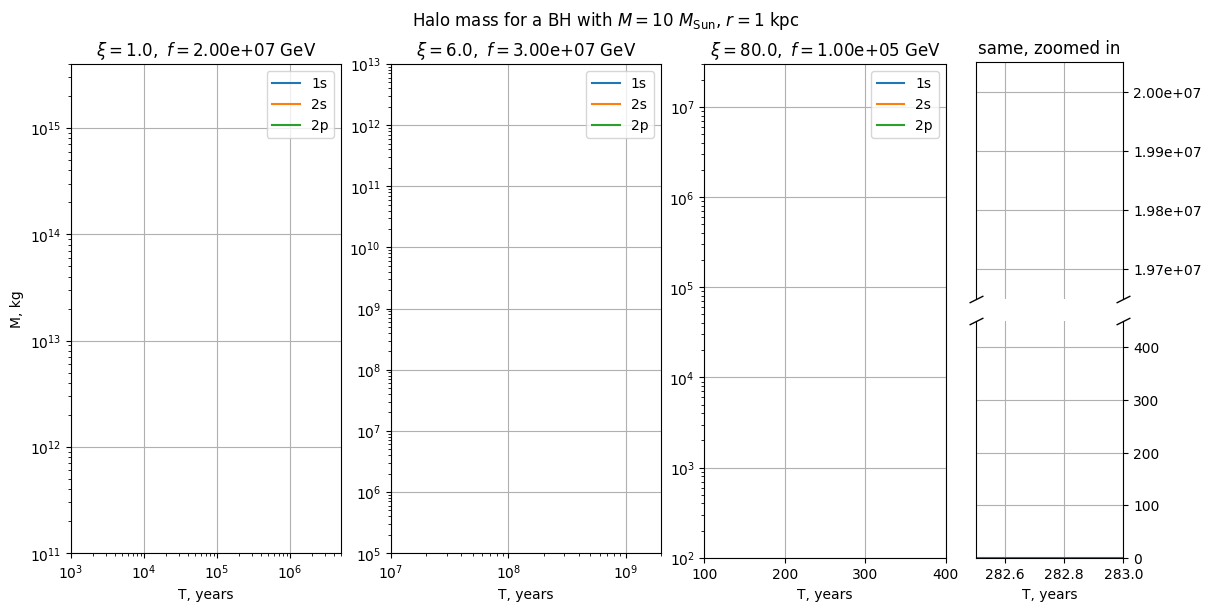

In [7]:
fig = plt.figure(figsize=(12, 6), layout="constrained")
gs0 = GridSpec(1, 3, figure=fig, width_ratios=[0.4, 0.4, 0.8])
gs1 = GridSpecFromSubplotSpec(1, 2, subplot_spec=gs0[2], width_ratios=[0.5, 0.5])
gs2 = GridSpecFromSubplotSpec(2, 1, subplot_spec=gs1[1])

axes = []
axes.append(fig.add_subplot(gs0[0]))
axes.append(fig.add_subplot(gs0[1]))
axes.append(fig.add_subplot(gs1[0]))

if (len(list_of_T_values)>1):
  for i in range(3):
    axes[i].plot(list_of_T_values[i], list_of_N_1s_mass_values[i], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
    axes[i].plot(list_of_T_values[i], list_of_N_2s_mass_values[i], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
    axes[i].plot(list_of_T_values[i], list_of_N_2p_mass_values[i], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
    axes[i].set_xlim(0,)
    axes[i].set_ylim(0,)

    axes[i].set_xlabel("T, years")
    if (i==0): axes[i].set_ylabel("M, kg")
    axes[i].set_title(r"$\xi=$"+f"{xi_values[i]}"+r"$,\ f=$"+f"{f_values[i]:.2e} GeV")

    axes[i].grid()
    axes[i].legend()

axes[0].set_xlim(1e3, 5e6)
axes[0].set_ylim(1e11, 4e15)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
# axes[0].set_xlim(2.2e6, 2.25e6)
# axes[0].set_ylim(1e15, 3e15)
# axes[0].set_xscale("linear")
# axes[0].set_yscale("linear")

axes[1].set_xlim(1e7, 2e9)
axes[1].set_ylim(1e5, 1e13)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
# axes[1].set_xlim(6.9e8, 7.1e8)
# axes[1].set_ylim(5e12, 8e12)
# axes[1].set_xscale("linear")
# axes[1].set_yscale("linear")

axes[2].set_xlim(1e2, 4e2)
axes[2].set_ylim(1e2, 3e7)
axes[2].set_xscale("linear")
axes[2].set_yscale("log")

ax_bottom = fig.add_subplot(gs2[1])
ax_top = fig.add_subplot(gs2[0], sharex=ax_bottom)
ax_bottom.plot(list_of_T_values[i], list_of_N_1s_mass_values[i], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
ax_top.plot(list_of_T_values[i], list_of_N_2p_mass_values[i], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
ax_bottom.set_xlim(282.5, 283)
ax_bottom.set_xscale("linear")
ax_bottom.set_ylim(0, 450)
ax_top.tick_params(bottom=False, labelbottom=False)
ax_bottom.set_yscale("linear")
ax_top.set_ylim(1.965e7, 2.005e7)
ax_top.set_yscale("linear")
ax_top.set_yticks([1.97e7, 1.98e7, 1.99e7, 2e7], minor=False)
ax_top.spines["bottom"].set_visible(False)
ax_bottom.spines["top"].set_visible(False)
#ax_top.set_title(r"$\xi=$"+f"{xi_values[2]}"+r"$,\ f=$"+f"{f_values[2]:.2e}")
ax_top.set_title("same, zoomed in")
ax_bottom.set_xlabel("T, years")
ax_top.grid()
ax_bottom.grid()
ax_top.yaxis.tick_right()
ax_top.yaxis.set_label_position("right")
ax_bottom.yaxis.tick_right()
ax_bottom.yaxis.set_label_position("right")

d = 0.5
kwargs = dict(
    marker=[(-1, -d), (1, d)],
    markersize=10,
    linestyle="none",
    color="k",
    mec="k",
    mew=1,
    clip_on=False,
)
ax_top.plot([0, 1], [0, 0], transform=ax_top.transAxes, **kwargs)
ax_bottom.plot([0, 1], [1, 1], transform=ax_bottom.transAxes, **kwargs)
ax_top.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2e}"))

plt.savefig("mass_over_time.pdf", bbox_inches="tight")
if (filename.startswith("star")):
  plt.suptitle(r"Halo mass for a star with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("BH")):
  plt.suptitle(r"Halo mass for a BH with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("IBH")):
  plt.suptitle(r"Halo mass for an IBH with $M=10^3\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("SBH")):
  plt.suptitle(r"Halo mass for a SBH with $M=10^5\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("Sun")):
  plt.suptitle(r"Halo mass for the Sun $M=M_{\text{Sun}}$, $r=8\ \text{kpc}$")
else:
  print("Unknown astro_regime")
plt.show()

In [8]:
def latex_sci_ticks(x, pos):
    if x == 0:
        return "$0$"
    mantissa, exp = f"{x:.2e}".split("e")
    return rf"${mantissa}\cdot 10^{{{int(exp)}}}$"

for i in range(len(list_of_T_values[0])):
  if (list_of_N_1s_density_values[0][i] == list_of_N_1s_density_values[0][i+1]):
    saturation_index = i
    break
print(f"Saturation index: {saturation_index}")
print(f"Saturation time: {list_of_T_values[0][saturation_index]:.3e}")

Saturation index: 9099
Saturation time: 2.227e+06


/tmp/ipykernel_513/4176056933.py:40: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axes[i].set_xlim(0,)
/tmp/ipykernel_513/4176056933.py:41: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  axes[i].set_ylim(0,)


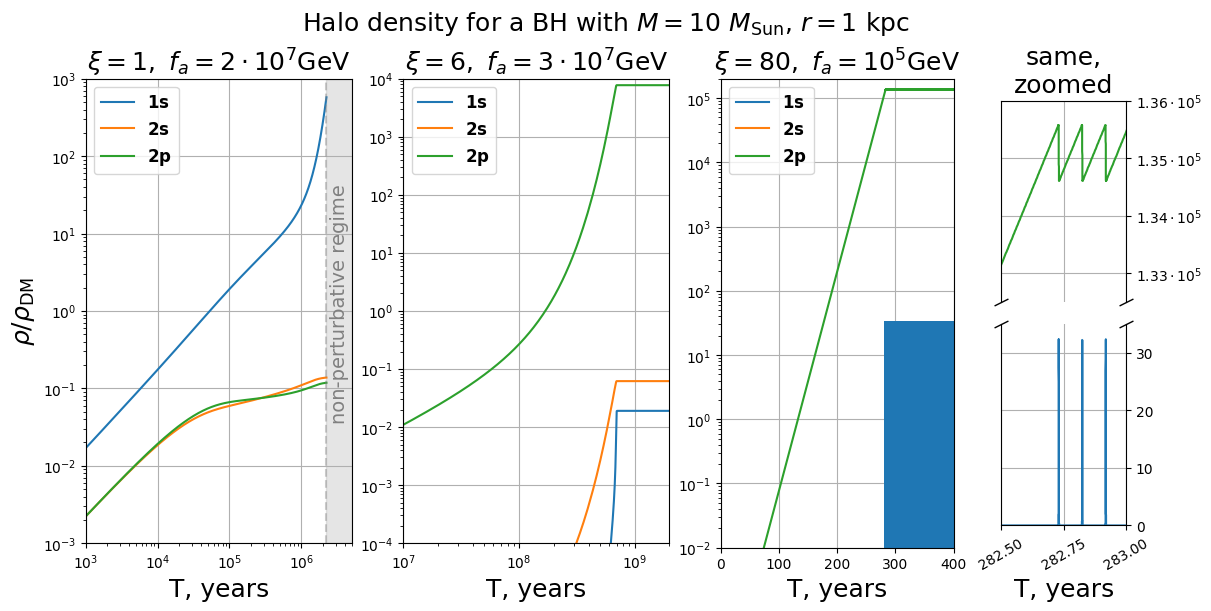

In [9]:
fig = plt.figure(figsize=(12, 6), layout="constrained")
gs0 = GridSpec(1, 3, figure=fig, width_ratios=[0.4, 0.4, 0.8])
gs1 = GridSpecFromSubplotSpec(1, 2, subplot_spec=gs0[2], width_ratios=[0.5, 0.5])
gs2 = GridSpecFromSubplotSpec(2, 1, subplot_spec=gs1[1])

axes = []
axes.append(fig.add_subplot(gs0[0]))
axes.append(fig.add_subplot(gs0[1]))
axes.append(fig.add_subplot(gs1[0]))

axes[0].set_xlim(1e3, 5e6)
axes[0].set_ylim(1e-3, 1e3)
axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[1].set_xlim(1e7, 2e9)
axes[1].set_ylim(1e-4, 1e4)
axes[1].set_xscale("log")
axes[1].set_yscale("log")

axes[2].set_xlim(1e2, 4e2)
axes[2].set_ylim(1e-2, 2e5)
axes[2].set_xscale("linear")
axes[2].set_yscale("log")

if (len(list_of_T_values)>1):
  for i in range(3):
    if (i==0):
      axes[i].plot(list_of_T_values[i][:saturation_index], list_of_N_1s_density_values[i][:saturation_index], color="C0", label=r"$\mathbf{1s}$")#, linestyle="none", marker=".", markersize=1)
      axes[i].plot(list_of_T_values[i][:saturation_index], list_of_N_2s_density_values[i][:saturation_index], color="C1", label=r"$\mathbf{2s}$")#, linestyle="none", marker=".", markersize=1)
      axes[i].plot(list_of_T_values[i][:saturation_index], list_of_N_2p_density_values[i][:saturation_index], color="C2", label=r"$\mathbf{2p}$")#, linestyle="none", marker=".", markersize=1)
      axes[i].axvline(x=list_of_T_values[i][saturation_index], color='gray', linestyle='--', alpha=0.4)
      axes[i].axvspan(xmin=list_of_T_values[i][saturation_index], xmax=axes[i].get_xlim()[1], color='gray', alpha=0.2)
      axes[i].text(x=2.5e6, y=0.04, s="non-perturbative regime", color='gray', rotation=90, fontsize=14)
    else:
      axes[i].plot(list_of_T_values[i], list_of_N_1s_density_values[i], color="C0", label=r"$\mathbf{1s}$")#, linestyle="none", marker=".", markersize=1)
      axes[i].plot(list_of_T_values[i], list_of_N_2s_density_values[i], color="C1", label=r"$\mathbf{2s}$")#, linestyle="none", marker=".", markersize=1)
      axes[i].plot(list_of_T_values[i], list_of_N_2p_density_values[i], color="C2", label=r"$\mathbf{2p}$")#, linestyle="none", marker=".", markersize=1)

    axes[i].set_xlim(0,)
    axes[i].set_ylim(0,)
    axes[i].set_xlabel("T, years", fontsize=18)
    if (i==0): axes[i].set_ylabel(r"$\rho/\rho_{\text{DM}}$", fontsize=18)

    mantissa, exp = f"{f_values[i]:.0e}".split("e")
    if (mantissa == "1"):
      latex_str = rf"$10^{{{int(exp)}}}$"
    else:
      latex_str = rf"${mantissa}\cdot 10^{{{int(exp)}}}$"
    axes[i].set_title(r"$\xi=$"+f"{xi_values[i]:.0f}"+r"$,\ f_a=$"+latex_str+"GeV", fontsize=18)

    axes[i].grid()
    axes[i].legend(loc='upper left', fontsize=12)

ax_bottom = fig.add_subplot(gs2[1])
ax_top = fig.add_subplot(gs2[0], sharex=ax_bottom)
ax_bottom.plot(list_of_T_values[i], list_of_N_1s_density_values[i], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
ax_top.plot(list_of_T_values[i], list_of_N_2p_density_values[i], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
ax_bottom.set_xlim(282.5, 283)
ax_bottom.set_xscale("linear")
ax_bottom.set_ylim(0, 35)
ax_top.tick_params(bottom=False, labelbottom=False)
ax_bottom.set_yscale("linear")
ax_top.set_ylim(1.325e5, 1.36e5)
ax_top.set_yscale("linear")
#ax_top.set_yticks([8.55e6, 8.6e6, 8.65e6, 8.7e6], minor=False)
ax_top.spines["bottom"].set_visible(False)
ax_bottom.spines["top"].set_visible(False)
#ax_top.set_title(r"$\xi=$"+f"{xi_values[2]}"+r"$,\ f=$"+f"{f_values[2]:.2e}")
ax_top.set_title("same,\nzoomed", fontsize=18)
ax_bottom.set_xlabel("T, years", fontsize=18)

d = 0.5
kwargs = dict(
    marker=[(-1, -d), (1, d)],
    markersize=10,
    linestyle="none",
    color="k",
    mec="k",
    mew=1,
    clip_on=False,
)
ax_top.plot([0, 1], [0, 0], transform=ax_top.transAxes, **kwargs)
ax_bottom.plot([0, 1], [1, 1], transform=ax_bottom.transAxes, **kwargs)
ax_top.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2e}"))
ax_top.grid()
ax_bottom.grid()
ax_top.yaxis.tick_right()
ax_top.yaxis.set_label_position("right")
ax_bottom.yaxis.tick_right()
ax_bottom.yaxis.set_label_position("right")
ax_bottom.set_xticks([282.5, 282.75, 283], labels=["282.50", "282.75", "283.00"], minor=False)
ax_bottom.tick_params(axis="x", labelrotation=30)
ax_top.yaxis.set_major_formatter(ticker.FuncFormatter(latex_sci_ticks))
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.savefig("density_over_time.pdf", bbox_inches="tight")

if (filename.startswith("star")):
  plt.suptitle(r"Halo density for a star with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$", fontsize=18)
elif (filename.startswith("BH")):
  plt.suptitle(r"Halo density for a BH with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$", fontsize=18)
elif (filename.startswith("IBH")):
  plt.suptitle(r"Halo density for an IBH with $M=10^3\ M_{\text{Sun}}$, $r=1\ \text{kpc}$", fontsize=18)
elif (filename.startswith("SBH")):
  plt.suptitle(r"Halo density for a SBH with $M=10^5\ M_{\text{Sun}}$, $r=1\ \text{kpc}$", fontsize=18)
elif (filename.startswith("Sun")):
  plt.suptitle(r"Halo density for the Sun $M=M_{\text{Sun}}$, $r=8\ \text{kpc}$", fontsize=18)
else:
  print("Unknown astro_regime")
plt.show()

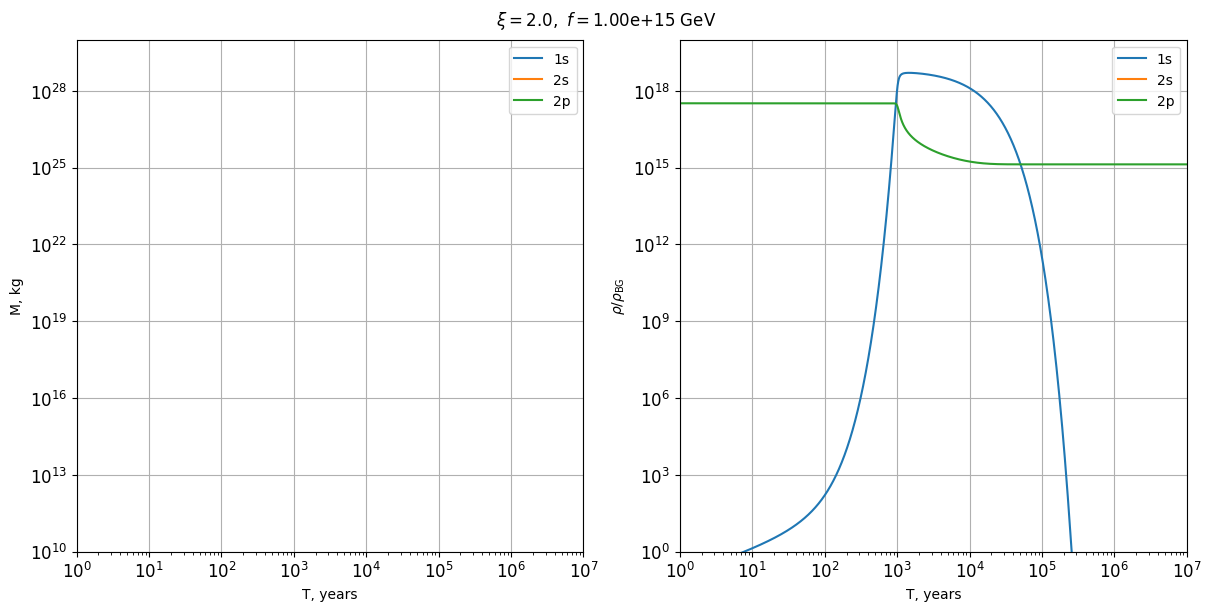

DM mass 2.133e-14 eV
Timescales:
Compton: 9.797e-10
coherent: 3.047e-03
1s: 1.180e+04
rel: 3.473e+36


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")

axes[0].plot(list_of_T_values[-1], list_of_N_1s_mass_values[-1], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[0].plot(list_of_T_values[-1], list_of_N_2s_mass_values[-1], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[0].plot(list_of_T_values[-1], list_of_N_2p_mass_values[-1], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[0].set_xlim(1, 1e7)
axes[0].set_ylim(1e10, 1e30)
axes[0].set_xlabel("T, years")
axes[0].set_ylabel("M, kg")
axes[0].grid()
axes[0].legend()

axes[1].plot(list_of_T_values[-1], list_of_N_1s_density_values[-1], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[1].plot(list_of_T_values[-1], list_of_N_2s_density_values[-1], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[1].plot(list_of_T_values[-1], list_of_N_2p_density_values[-1], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[1].set_xlim(1, 1e7)
axes[1].set_ylim(1e0, 1e20)
axes[1].set_xlabel("T, years")
axes[1].set_ylabel(r"$\rho/\rho_{\text{BG}}$")
axes[1].grid()
axes[1].legend()

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[1].set_xscale("log")
axes[1].set_yscale("log")

fig.suptitle(r"$\xi=$"+f"{xi_values[-1]}"+r"$,\ f=$"+f"{f_values[-1]:.2e} GeV")
plt.show()

tau_rel = 9.05699e9 * f_tilde_values[-1]**4 * m_tilde_values[-1]**3 * rho_tilde**(-2) * v_tilde**2
tau_1s = 1.11189e11 * m_tilde_values[-1]**(-6) * M_tilde**(-5)
tau_coherent = 0.0065 * m_tilde_values[-1]**(-1) * v_tilde**(-2)
tau_Compton = 2.09e-9 * m_tilde_values[-1]**(-1)

print(f"DM mass {m_tilde_values[-1]*1e-14:.3e} eV")
print("Timescales:")
print(f"Compton: {tau_Compton:.3e}")
print(f"coherent: {tau_coherent:.3e}")
print(f"1s: {tau_1s:.3e}")
print(f"rel: {tau_rel:.3e}")

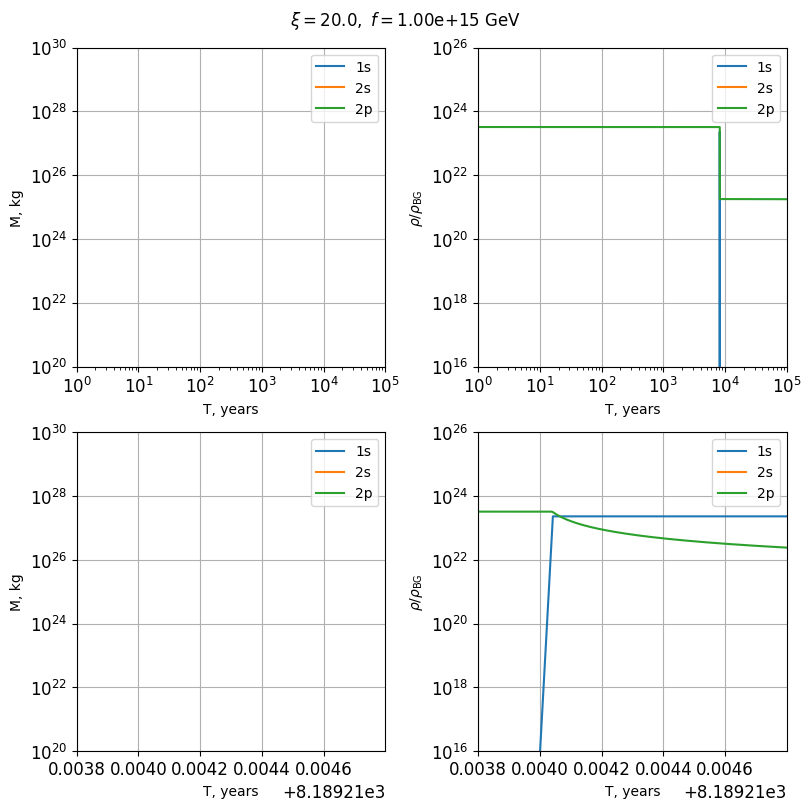

DM mass 2.133e-13 eV
Timescales:
Compton: 9.797e-11 years
coherent: 3.047e-04 years
1s: 1.180e-02 years
rel: 3.473e+39 years


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8), layout="constrained")

axes[0][0].plot(list_of_T_values[-2], list_of_N_1s_mass_values[-2], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[0][0].plot(list_of_T_values[-2], list_of_N_2s_mass_values[-2], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[0][0].plot(list_of_T_values[-2], list_of_N_2p_mass_values[-2], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[0][0].set_xlim(1, 1e5)
axes[0][0].set_ylim(1e20, 1e30)
axes[0][0].set_xlabel("T, years")
axes[0][0].set_ylabel("M, kg")
axes[0][0].grid()
axes[0][0].legend()

axes[0][1].plot(list_of_T_values[-2], list_of_N_1s_density_values[-2], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[0][1].plot(list_of_T_values[-2], list_of_N_2s_density_values[-2], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[0][1].plot(list_of_T_values[-2], list_of_N_2p_density_values[-2], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[0][1].set_xlim(1, 1e5)
axes[0][1].set_ylim(1e16, 1e26)
axes[0][1].set_xlabel("T, years")
axes[0][1].set_ylabel(r"$\rho/\rho_{\text{BG}}$")
axes[0][1].grid()
axes[0][1].legend()

axes[0][0].set_xscale("log")
axes[0][0].set_yscale("log")
axes[0][1].set_xscale("log")
axes[0][1].set_yscale("log")

axes[1][0].plot(list_of_T_values[-2], list_of_N_1s_mass_values[-2], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[1][0].plot(list_of_T_values[-2], list_of_N_2s_mass_values[-2], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[1][0].plot(list_of_T_values[-2], list_of_N_2p_mass_values[-2], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[1][0].set_xlim(8189.2138, 8189.2148)
axes[1][0].set_ylim(1e20, 1e30)
axes[1][0].set_xlabel("T, years")
axes[1][0].set_ylabel("M, kg")
axes[1][0].grid()
axes[1][0].legend()

axes[1][1].plot(list_of_T_values[-2], list_of_N_1s_density_values[-2], color="C0", label="1s")#, linestyle="none", marker=".", markersize=1)
axes[1][1].plot(list_of_T_values[-2], list_of_N_2s_density_values[-2], color="C1", label="2s")#, linestyle="none", marker=".", markersize=1)
axes[1][1].plot(list_of_T_values[-2], list_of_N_2p_density_values[-2], color="C2", label="2p")#, linestyle="none", marker=".", markersize=1)
axes[1][1].set_xlim(8189.2138, 8189.2148)
axes[1][1].set_ylim(1e16, 1e26)
axes[1][1].set_xlabel("T, years")
axes[1][1].set_ylabel(r"$\rho/\rho_{\text{BG}}$")
axes[1][1].grid()
axes[1][1].legend()

axes[1][0].set_yscale("log")
axes[1][1].set_yscale("log")

fig.suptitle(r"$\xi=$"+f"{xi_values[-2]}"+r"$,\ f=$"+f"{f_values[-2]:.2e} GeV")
plt.savefig("duperradiance.pdf")
plt.show()

tau_rel = 9.05699e9 * f_tilde_values[-2]**4 * m_tilde_values[-2]**3 * rho_tilde**(-2) * v_tilde**2
tau_1s = 1.11189e11 * m_tilde_values[-2]**(-6) * M_tilde**(-5)
tau_coherent = 0.0065 * m_tilde_values[-2]**(-1) * v_tilde**(-2)
tau_Compton = 2.09e-9 * m_tilde_values[-2]**(-1)

print(f"DM mass {m_tilde_values[-2]*1e-14:.3e} eV")
print("Timescales:")
print(f"Compton: {tau_Compton:.3e} years")
print(f"coherent: {tau_coherent:.3e} years")
print(f"1s: {tau_1s:.3e} years")
print(f"rel: {tau_rel:.3e} years")